# Steps 5-6 - Evaluation, confidence intervals, hypothesis tests (microwave, context features)
UK-DALE has no labelled faults, so we **inject** artificial *sustained* faults (10 readings = about 1 minute each) into the TEST period:
**spike** (power x1.5-2.5 + 150 W), **drop** (power x0.3-0.6), **drift** (power x0.82, an 18 % reduction). Features are recomputed after injection.
Faults = about 10 % of the steady test rows. Rows in the 10 readings after a fault are excluded from the normal set (recovery period).
Everything is repeated **30 times** (different seeds: fault positions and types, 80 % training subsample, model randomness); all models see the same data in a repetition (paired).

In [1]:
import os, sys, json, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sys.path.append("..")
from features import roll_feats, W
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
SEED, N_REPS, FAULT_FRAC, SEG, CONTAM, MAX_FIT = 42, 30, 0.10, 10, 0.02, 5000
sns.set_theme()
df = pd.read_csv("../data/microwave_clean.csv", index_col=0, parse_dates=True)
P0, D0 = df.power.values.astype(float), df.delta.values.astype(float)
steady = (df.active & df.active.shift(1, fill_value=False)).values
is_tr, is_te = (df.split == "train").values, (df.split == "test").values
F0 = roll_feats(P0, D0); Xtr_all = F0[is_tr & steady]; mask_eval = is_te & steady; te_idx = np.where(mask_eval)[0]
print("train rows:", len(Xtr_all), "| steady test rows:", len(te_idx))

def inject(rng):
    n_seg = max(8, int(FAULT_FRAC * len(te_idx) / SEG)); p = P0.copy(); lab = np.zeros(len(p), bool); kind = np.full(len(p), "", dtype=object)
    for s in rng.choice(te_idx, n_seg, replace=False):
        e = min(len(p), s + SEG); k = rng.choice(["spike", "drop", "drift"])
        if k == "spike": p[s:e] = P0[s:e] * rng.uniform(1.5, 2.5) + 150
        elif k == "drop": p[s:e] = P0[s:e] * rng.uniform(.3, .6)
        else: p[s:e] = P0[s:e] * 0.82
        lab[s:e] = True; kind[s:e] = k
    sh = p - P0; d = D0 + sh - np.r_[0, sh[:-1]]
    near = pd.Series(lab).rolling(W, min_periods=1).max().astype(bool).values       # fault + recovery rows
    return roll_feats(p, d), lab, near, kind

def models(seed):
    return {"IF": IsolationForest(n_estimators=200, contamination=CONTAM, random_state=seed),
            "LOF": LocalOutlierFactor(n_neighbors=30, contamination=CONTAM, novelty=True),
            "OCSVM": OneClassSVM(nu=CONTAM, gamma="scale")}

train rows: 5310 | steady test rows: 751


## 5.1 Run the 30 repetitions

In [2]:
res, bytype = [], []
for r in range(N_REPS):
    rng = np.random.default_rng(SEED + r)
    tr = Xtr_all[rng.choice(len(Xtr_all), min(MAX_FIT, int(.8 * len(Xtr_all))), replace=False)]
    F, lab, near, kind = inject(rng); nm, fm = mask_eval & ~near, mask_eval & lab
    sc = StandardScaler().fit(tr); tr_s, n_s, f_s, fk = sc.transform(tr), sc.transform(F[nm]), sc.transform(F[fm]), kind[fm]
    for name, m in models(SEED + r).items():
        t = time.time(); m.fit(tr_s + rng.normal(0, 1e-3, tr_s.shape) if name == "LOF" else tr_s); fit_s = time.time() - t
        pn, pf = m.predict(n_s) == -1, m.predict(f_s) == -1
        tp, fp = pf.sum(), pn.sum(); prec = tp / (tp + fp) if tp + fp else 0; rec = tp / len(pf)
        res.append(dict(rep=r, model=name, detection=rec, false_alarm=fp / len(pn), precision=prec,
                        f1=2 * prec * rec / (prec + rec) if prec + rec else 0, fit_s=fit_s))
        for k in ["spike", "drop", "drift"]:
            bytype.append(dict(rep=r, model=name, fault=k, detection=pf[fk == k].mean() if (fk == k).any() else np.nan))
res, bytype = pd.DataFrame(res), pd.DataFrame(bytype); res.to_csv("../data/eval_runs.csv", index=False)
res.groupby("model")[["detection", "false_alarm", "precision", "f1"]].mean().round(3)

,detection,false_alarm,precision,f1
model,,,,
IF,0.081,0.016,0.233,0.119
LOF,0.305,0.023,0.432,0.353
OCSVM,0.197,0.031,0.258,0.219


## 5.2 Detection by fault type

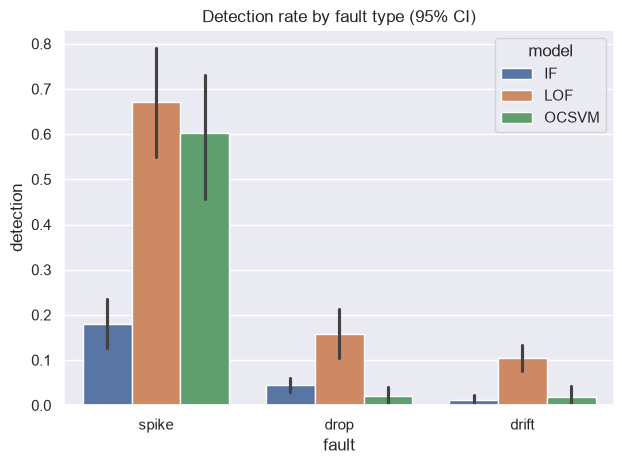

In [3]:
sns.barplot(data=bytype, x="fault", y="detection", hue="model", errorbar=("ci", 95)); plt.title("Detection rate by fault type (95% CI)")
plt.tight_layout(); plt.savefig("../data/fig_by_fault.png", dpi=120); plt.show()

## 6.1 95 % confidence intervals (t-interval of the mean over 30 runs)

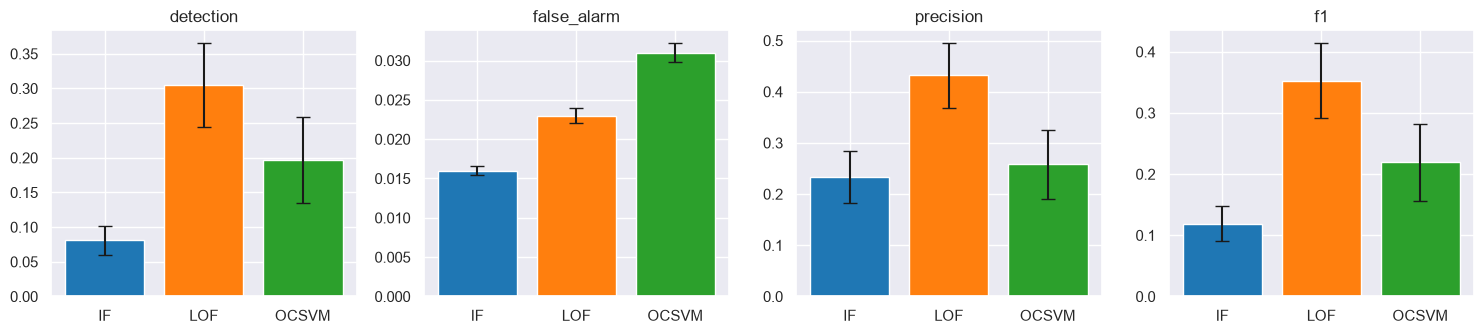

metric,detection,f1,false_alarm,precision
model,,,,
IF,"0.081 [0.06, 0.102]","0.119 [0.09, 0.148]","0.016 [0.015, 0.016]","0.233 [0.183, 0.284]"
LOF,"0.305 [0.245, 0.366]","0.353 [0.292, 0.414]","0.023 [0.022, 0.024]","0.432 [0.369, 0.495]"
OCSVM,"0.197 [0.135, 0.259]","0.219 [0.156, 0.282]","0.031 [0.03, 0.032]","0.258 [0.19, 0.326]"


In [4]:
def ci(x):
    h = stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)); return x.mean(), x.mean() - h, x.mean() + h, h
mets = ["detection", "false_alarm", "precision", "f1"]; rows = []
for mn, g in res.groupby("model"):
    for me in mets:
        m, lo, hi, h = ci(g[me]); rows.append(dict(model=mn, metric=me, mean=round(m, 3), ci_low=round(lo, 3), ci_high=round(hi, 3), half=h))
cit = pd.DataFrame(rows); cit.drop(columns="half").to_csv("../data/ci_table.csv", index=False)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
for a_, me in zip(ax, mets):
    d = cit[cit.metric == me]; a_.bar(d.model, d["mean"], yerr=d.half, capsize=5, color=["tab:blue", "tab:orange", "tab:green"]); a_.set_title(me)
plt.tight_layout(); plt.savefig("../data/fig_ci.png", dpi=120); plt.show()
pv = lambda c: cit.pivot(index="model", columns="metric", values=c).round(3).astype(str)
pv("mean") + " [" + pv("ci_low") + ", " + pv("ci_high") + "]"

## 6.2 Hypothesis tests on F1 (alpha = 0.05)
**H0:** the models have equal F1. **H1:** at least one differs. Friedman test, then pairwise Wilcoxon signed-rank tests with Bonferroni
correction (x3); paired t-test for reference. *Caveat:* repetitions reuse the same underlying test period, so p-values are indicative.

Friedman chi2 = 40.35, p = 1.73e-09


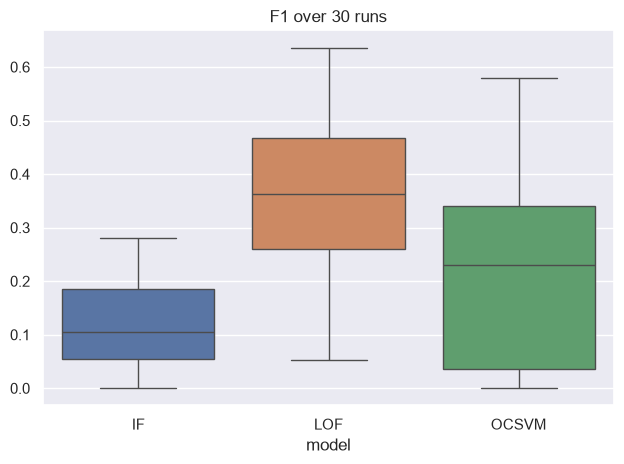

,pair,mean_F1_diff,wilcoxon_p,bonferroni_p,paired_t_p,significant
0,IF vs LOF,-0.2341,9.313226e-09,2.793968e-08,1.229358e-10,True
1,IF vs OCSVM,-0.1006,1.226398e-03,3.679193e-03,2.650929e-04,True
2,LOF vs OCSVM,0.1335,1.862645e-09,5.587935e-09,2.685938e-11,True


In [5]:
piv = res.pivot(index="rep", columns="model", values="f1")
fr = stats.friedmanchisquare(piv.IF, piv.LOF, piv.OCSVM); print(f"Friedman chi2 = {fr.statistic:.2f}, p = {fr.pvalue:.2e}")
tests = []
for a, b in [("IF", "LOF"), ("IF", "OCSVM"), ("LOF", "OCSVM")]:
    try: w = stats.wilcoxon(piv[a], piv[b]).pvalue
    except ValueError: w = np.nan
    pb = min(1.0, w * 3) if w == w else np.nan
    tests.append(dict(pair=f"{a} vs {b}", mean_F1_diff=round((piv[a] - piv[b]).mean(), 4), wilcoxon_p=w,
                      bonferroni_p=pb, paired_t_p=stats.ttest_rel(piv[a], piv[b]).pvalue, significant=bool(pb < .05) if pb == pb else False))
tests = pd.DataFrame(tests); tests.to_csv("../data/hypothesis_tests.csv", index=False)
sns.boxplot(data=piv); plt.title("F1 over 30 runs"); plt.tight_layout(); plt.savefig("../data/fig_f1_box.png", dpi=120); plt.show(); tests

## 6.3 Save metrics for the dashboard

In [6]:
tl = pd.read_csv("../data/training_log.csv").set_index("model"); mm = res.groupby("model")[["detection", "false_alarm", "fit_s"]].mean()
json.dump({"microwave": {"models": {k: {"detection_rate": round(float(v.detection), 3), "false_alarm_rate": round(float(v.false_alarm), 3),
          "fit_s": round(float(v.fit_s), 3), "predict_s": float(tl.loc[k, "predict_s"])} for k, v in mm.iterrows()}}},
          open("../models/metrics.json", "w"), indent=1)
print("saved ../models/metrics.json")

saved ../models/metrics.json
